# 07 · Oportunidades e recomendações

**Pergunta:** onde estão as alavancas de valor e quanto cada uma vale?

Cada oportunidade é dimensionada sobre os **últimos 12 meses completos (ago/2017 a jul/2018)**, para que os números representem um ano de operação. As estimativas são de ordem de grandeza: indicam prioridade, não substituem um piloto.

## Principais conclusões

1. **Logística em RJ e Nordeste.** Levar cada estado à taxa de atraso de SP (4,3%) evitaria cerca de 2.400 atrasos por ano (44% do total) e 1.300 notas 1–2, subindo a nota média de 4,13 para 4,20. RJ e Nordeste concentram 69% desse ganho.
2. **Qualidade de vendedores.** 84 vendedores críticos (lentos e mal avaliados) geram 27,5% das notas baixas com 17% da receita. Trazê-los à média dos demais evitaria cerca de 1.000 notas baixas por ano.
3. **Expansão com oferta local.** Se Norte e Nordeste atingissem a penetração do Centro-Oeste, a receita cresceria até R$ 2,5 milhões por ano (+21%). No Nordeste, o vendedor local entrega em 14 dias, contra 20, com frete de 11% do pedido, contra 25%.
4. **Recompra.** Cada ponto percentual a mais vale cerca de R$ 114 mil por ano: uma alavanca menor que as anteriores, mas barata de testar.
5. **Prazo prometido.** A promessa cobre a cauda de entregas lentas, e encurtá-la agora aumentaria os atrasos. Primeiro é preciso reduzir a variabilidade da entrega.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from olist import config, data, prep, viz
from olist.viz import CORES, brl, num, pct

viz.aplicar_estilo()

In [2]:
t = data.carregar_todas()
pedidos = prep.carregar_base_pedidos()
u12 = pedidos[prep.no_periodo(pedidos.order_purchase_timestamp, "2017-08-01", "2018-07-31")].copy()
validos12, ent12 = u12[u12.valido], u12[u12.entregue].copy()
aval12 = ent12.dropna(subset=["review_score"])

pd.Series({
    "Pedidos válidos": num(len(validos12)),
    "Receita (GMV)": brl(validos12.gmv.sum()),
    "Clientes únicos": num(validos12.customer_unique_id.nunique()),
    "Pedidos entregues": num(len(ent12)),
    "Taxa de atraso": pct(ent12.atrasado.mean()),
    "Nota média": num(aval12.review_score.mean(), 2),
}).to_frame("últimos 12 meses")

,últimos 12 meses
Pedidos válidos,73.194
Receita (GMV),"R$ 11,8 mi"
Clientes únicos,71.141
Pedidos entregues,72.048
Taxa de atraso,"7,6%"
Nota média,"4,13"


## Alavanca 1 · Reduzir atrasos fora de SP

**Meta:** levar cada estado, no máximo, à taxa de atraso de São Paulo, que tem a operação mais madura.

In [3]:
nota_por_situacao = aval12.groupby("atrasado").agg(nota=("review_score", "mean"), baixa=("nota_baixa", "mean"))
uf = ent12.groupby("customer_state").agg(pedidos=("order_id", "size"), atraso=("atrasado", "mean"))
meta_atraso = uf.loc["SP", "atraso"]
uf["evitaveis"] = (uf.atraso - meta_atraso).clip(lower=0) * uf.pedidos
evitaveis = uf.evitaveis.sum()

taxa_avaliacao = len(aval12) / len(ent12)
baixas_evitadas = evitaveis * taxa_avaliacao * (nota_por_situacao.loc[1, "baixa"] - nota_por_situacao.loc[0, "baixa"])
nota_atual = aval12.review_score.mean()
nota_nova = nota_atual + evitaveis * taxa_avaliacao * (nota_por_situacao.loc[0, "nota"] - nota_por_situacao.loc[1, "nota"]) / len(aval12)
taxa_nova = (ent12.atrasado.sum() - evitaveis) / len(ent12)
participacao_rj_ne = uf.loc[["RJ", "BA", "CE", "PE", "MA", "AL", "PI", "SE", "PB", "RN"], "evitaveis"].sum() / evitaveis

print(f"Meta (taxa de SP): {pct(meta_atraso)}")
print(f"Atrasos evitáveis por ano: {num(evitaveis)} ({pct(evitaveis / ent12.atrasado.sum())} dos atrasos)")
print(f"Taxa de atraso: {pct(ent12.atrasado.mean())} -> {pct(taxa_nova)}")
print(f"Notas 1–2 evitadas por ano: {num(baixas_evitadas)} | nota média: {num(nota_atual, 2)} -> {num(nota_nova, 2)}")
print(f"RJ e Nordeste concentram {pct(participacao_rj_ne)} dos atrasos evitáveis")

Meta (taxa de SP): 4,3%
Atrasos evitáveis por ano: 2.421 (44,1% dos atrasos)
Taxa de atraso: 7,6% -> 4,3%
Notas 1–2 evitadas por ano: 1.318 | nota média: 4,13 -> 4,20
RJ e Nordeste concentram 69,4% dos atrasos evitáveis


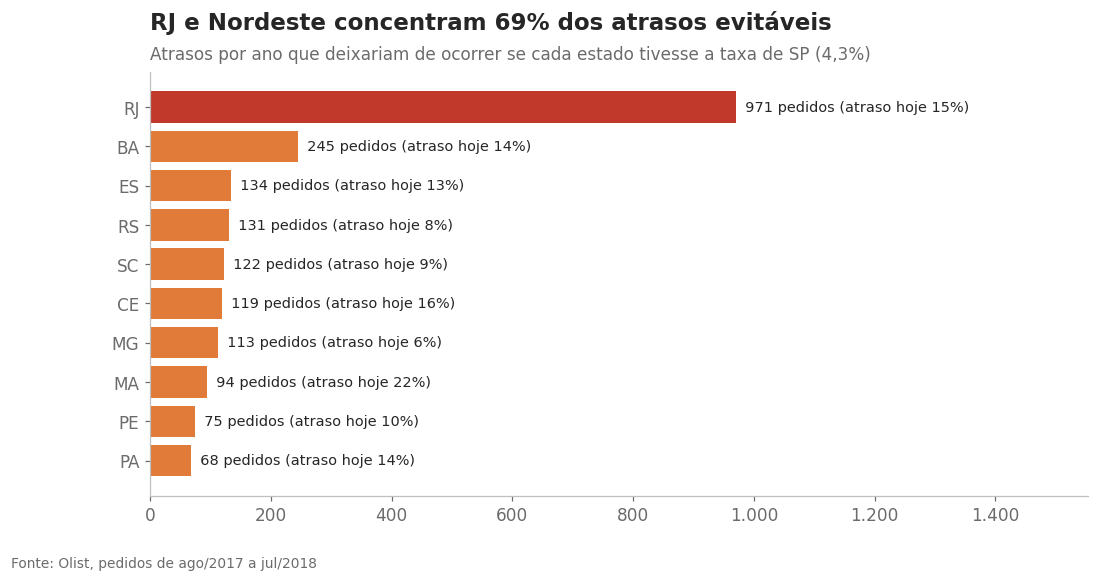

In [4]:
top_uf = uf.sort_values("evitaveis", ascending=False).head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(top_uf.index, top_uf.evitaveis, color=[CORES["negativo"] if u == "RJ" else CORES["destaque"] for u in top_uf.index])
for yi, (ev, at) in enumerate(zip(top_uf.evitaveis, top_uf.atraso)):
    ax.text(ev, yi, f"  {num(ev)} pedidos (atraso hoje {pct(at, 0)})", va="center", fontsize=9.5)
ax.set_xlim(0, top_uf.evitaveis.max() * 1.6)
ax.xaxis.set_major_formatter(viz.eixo_num)
ax.grid(axis="y", visible=False)
viz.titulo(ax, f"RJ e Nordeste concentram {pct(participacao_rj_ne, 0)} dos atrasos evitáveis",
           f"Atrasos por ano que deixariam de ocorrer se cada estado tivesse a taxa de SP ({pct(meta_atraso)})")
viz.fonte(fig, "Fonte: Olist, pedidos de ago/2017 a jul/2018")
viz.salvar(fig, "07_atrasos_evitaveis")

## Alavanca 2 · Programa de qualidade de vendedores

Vendedores com pelo menos 30 pedidos entregues nos últimos 12 meses, classificados pela nota média e pelo tempo mediano para postar o pedido.

In [5]:
vend = ent12.groupby("seller_id").agg(
    pedidos=("order_id", "size"), nota=("review_score", "mean"), postagem=("dias_postagem", "median"),
    atraso=("atrasado", "mean"), gmv=("gmv", "sum"), baixas=("nota_baixa", "sum"), uf=("seller_state", "first"))
vend = vend[vend.pedidos >= 30].copy()
corte_nota, corte_postagem = 4.0, vend.postagem.median()
vend["grupo"] = np.select(
    [(vend.nota >= corte_nota) & (vend.postagem <= corte_postagem), (vend.nota >= corte_nota), (vend.postagem <= corte_postagem)],
    ["Estrelas", "Bem avaliados, mas lentos", "Rápidos, mas mal avaliados"], default="Críticos")
ordem_grupos = ["Estrelas", "Bem avaliados, mas lentos", "Rápidos, mas mal avaliados", "Críticos"]
grupos = vend.groupby("grupo").agg(vendedores=("pedidos", "size"), gmv=("gmv", "sum"), baixas=("baixas", "sum"), pedidos=("pedidos", "sum"),
                                   nota=("nota", "mean"), atraso=("atraso", "mean"), postagem=("postagem", "median")).reindex(ordem_grupos)
grupos["% da receita"] = grupos.gmv / grupos.gmv.sum()
grupos["% das notas baixas"] = grupos.baixas / grupos.baixas.sum()
# Se os críticos tivessem a taxa de notas baixas da média dos demais vendedores
taxa_demais = grupos.drop("Críticos").baixas.sum() / grupos.drop("Críticos").pedidos.sum()
baixas_criticos_evitaveis = grupos.loc["Críticos", "baixas"] - grupos.loc["Críticos", "pedidos"] * taxa_demais
print(f"Corte: nota {corte_nota} e postagem em até {num(corte_postagem, 1)} dias (mediana)")
print(f"Notas 1–2 evitadas por ano se os críticos tivessem a taxa dos demais ({pct(taxa_demais)}): {num(baixas_criticos_evitaveis)}")
grupos[["vendedores", "% da receita", "% das notas baixas", "nota", "atraso", "postagem"]].assign(
    **{"% da receita": grupos["% da receita"].map(pct), "% das notas baixas": grupos["% das notas baixas"].map(pct)},
    nota=grupos.nota.round(2), atraso=grupos.atraso.map(pct), postagem=grupos.postagem.round(1))

Corte: nota 4.0 e postagem em até 1,6 dias (mediana)
Notas 1–2 evitadas por ano se os críticos tivessem a taxa dos demais (11,9%): 1.035


,vendedores,% da receita,% das notas baixas,nota,atraso,postagem
grupo,,,,,,
Estrelas,205,"35,4%","26,4%",4.32,"5,0%",1.10
"Bem avaliados, mas lentos",163,"40,4%","34,2%",4.23,"7,0%",2.40
"Rápidos, mas mal avaliados",43,"7,0%","11,9%",3.80,"9,1%",1.20
Críticos,84,"17,2%","27,5%",3.70,"12,5%",3.20


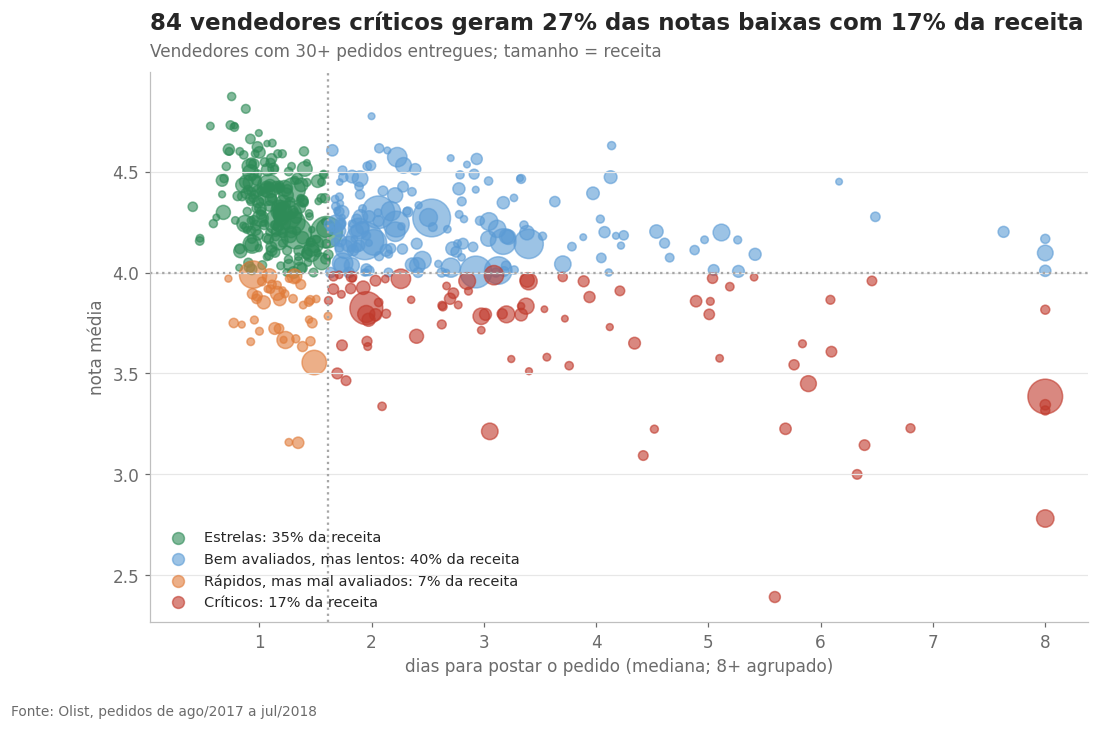

In [6]:
cores_grupo = {"Estrelas": CORES["positivo"], "Bem avaliados, mas lentos": CORES["secundaria"],
               "Rápidos, mas mal avaliados": CORES["destaque"], "Críticos": CORES["negativo"]}
fig, ax = plt.subplots(figsize=(11, 6.5))
for grupo in ordem_grupos:
    g = vend[vend.grupo == grupo]
    ax.scatter(g.postagem.clip(upper=8), g.nota, s=g.gmv / vend.gmv.max() * 600 + 12, color=cores_grupo[grupo], alpha=0.6,
               label=f"{grupo}: {pct(grupos.loc[grupo, '% da receita'], 0)} da receita")
ax.axhline(corte_nota, color=CORES["neutro"], ls=":")
ax.axvline(corte_postagem, color=CORES["neutro"], ls=":")
ax.set_xlabel("dias para postar o pedido (mediana; 8+ agrupado)")
ax.set_ylabel("nota média")
legenda = ax.legend(loc="lower left", fontsize=9.5)
for marcador in legenda.legend_handles:
    marcador.set_sizes([60])
criticos = grupos.loc["Críticos"]
viz.titulo(ax, f"{num(criticos.vendedores)} vendedores críticos geram {pct(criticos['% das notas baixas'], 0)} das notas baixas com {pct(criticos['% da receita'], 0)} da receita",
           "Vendedores com 30+ pedidos entregues; tamanho = receita")
viz.fonte(fig, "Fonte: Olist, pedidos de ago/2017 a jul/2018")
viz.salvar(fig, "07_vendedores_quadrante")

## Alavanca 3 · Expandir no Norte e Nordeste com oferta local

O Nordeste tem 27% da população e só 12% da receita. Quase todo pedido da região vem de vendedores de outras regiões, o que alonga o prazo e encarece o frete.

In [7]:
populacao = data.carregar_populacao_uf().set_index("uf").populacao
clientes_uf = validos12.groupby("customer_state").customer_unique_id.nunique()
gmv_por_cliente = validos12.groupby("regiao").gmv.sum() / validos12.groupby("regiao").customer_unique_id.nunique()
regiao = pd.DataFrame({
    "clientes": clientes_uf.groupby(clientes_uf.index.map(config.UF_REGIAO)).sum(),
    "populacao": populacao.groupby(populacao.index.map(config.UF_REGIAO)).sum(),
}).reindex(config.ORDEM_REGIOES)
regiao["clientes_100k"] = regiao.clientes / regiao.populacao * 1e5
meta_penetracao = regiao.loc["Centro-Oeste", "clientes_100k"]
alvo = regiao.loc[["Nordeste", "Norte"]].copy()
alvo["clientes_extra"] = (meta_penetracao - alvo.clientes_100k) * alvo.populacao / 1e5
alvo["receita_extra"] = alvo.clientes_extra * gmv_por_cliente.reindex(alvo.index)
receita_expansao = alvo.receita_extra.sum()
print(f"Meta: penetração do Centro-Oeste ({num(meta_penetracao)} clientes por 100 mil hab.)")
print(alvo.assign(clientes_100k=alvo.clientes_100k.round(0), clientes_extra=alvo.clientes_extra.map(num), receita_extra=alvo.receita_extra.map(brl)).to_string())
print(f"Receita potencial adicional por ano: {brl(receita_expansao)} ({pct(receita_expansao / validos12.gmv.sum())} da receita atual)")

Meta: penetração do Centro-Oeste (26 clientes por 100 mil hab.)
          clientes     populacao  clientes_100k clientes_extra receita_extra
Nordeste      6822 56,760,780.00          12.00          8.153     R$ 1,7 mi
Norte         1288 18,182,253.00           7.00          3.509    R$ 815 mil
Receita potencial adicional por ano: R$ 2,5 mi (21,4% da receita atual)


                                       pedidos  prazo  frete atraso
regiao       origem                                                
Centro-Oeste vendedor da região            209   9.00  16,2%   2,4%
             vendedor de outra região     5401  15.20  20,2%   6,7%
Nordeste     vendedor da região            432  14.00  11,1%   9,3%
             vendedor de outra região     8583  20.30  24,6%  12,9%
Sul          vendedor da região           3046  10.60  15,8%   3,6%
             vendedor de outra região    10721  15.00  21,3%   6,6%


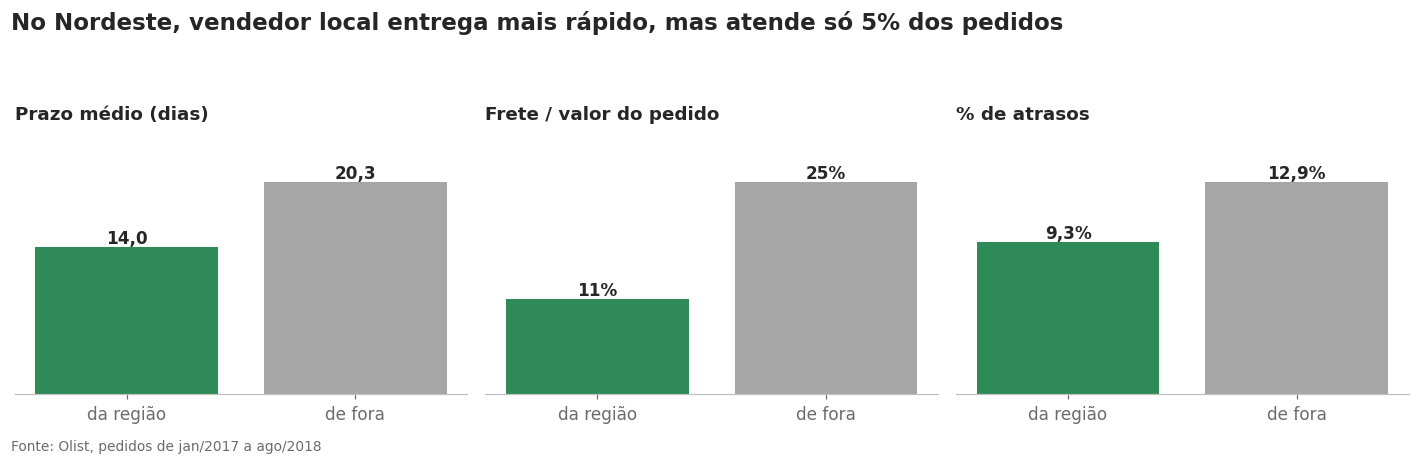

In [8]:
ent = pedidos[pedidos.entregue].copy()
ent["origem"] = np.where(ent.regiao == ent.regiao_seller, "vendedor da região", "vendedor de outra região")
comparacao = ent[ent.regiao.isin(["Nordeste", "Sul", "Centro-Oeste"])].groupby(["regiao", "origem"]).agg(
    pedidos=("order_id", "size"), prazo=("dias_entrega", "mean"), frete=("perc_frete", "median"), atraso=("atrasado", "mean"))
print(comparacao.assign(prazo=comparacao.prazo.round(1), frete=comparacao.frete.map(pct), atraso=comparacao.atraso.map(pct)).to_string())

ne = comparacao.loc["Nordeste"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (coluna, nome, fmt) in zip(axes, [("prazo", "Prazo médio (dias)", lambda v: num(v, 1)),
                                         ("frete", "Frete / valor do pedido", lambda v: pct(v, 0)),
                                         ("atraso", "% de atrasos", lambda v: pct(v, 1))]):
    barras = ax.bar(["da região", "de fora"], ne.loc[["vendedor da região", "vendedor de outra região"], coluna],
                    color=[CORES["positivo"], CORES["neutro"]])
    for barra in barras:
        ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(), fmt(barra.get_height()), ha="center", va="bottom", fontweight="bold")
    ax.set_title(nome, fontsize=12, pad=6)
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    ax.set_ylim(0, ne[coluna].max() * 1.25)
local_ne = (ent.loc[ent.regiao == "Nordeste", "origem"] == "vendedor da região").mean()
fig.suptitle(f"No Nordeste, vendedor local entrega mais rápido, mas atende só {pct(local_ne, 0)} dos pedidos",
             x=0.01, ha="left", fontsize=15, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.9))
viz.fonte(fig)
viz.salvar(fig, "07_oferta_local_nordeste")

## Alavanca 4 · Recompra e relacionamento

Com recompra de cerca de 2%, praticamente todo cliente é novo. Cada ponto percentual a mais de clientes que voltam vale:

In [9]:
clientes12 = validos12.customer_unique_id.nunique()
ticket12 = validos12.gmv.mean()
receita_1pp = clientes12 * 0.01 * ticket12
gasto = validos12.groupby("customer_unique_id").gmv.sum()
alto_valor = (gasto >= gasto.quantile(0.8)).sum()
print(f"Clientes nos últimos 12 meses: {num(clientes12)} | ticket médio: {brl(ticket12)}")
print(f"+1 p.p. de recompra = {num(clientes12 * 0.01)} pedidos e {brl(receita_1pp)} por ano")
print(f"Clientes de alto valor (20% que mais gastaram) para campanhas de reativação: {num(alto_valor)}")

Clientes nos últimos 12 meses: 71.141 | ticket médio: R$ 161
+1 p.p. de recompra = 711 pedidos e R$ 114 mil por ano
Clientes de alto valor (20% que mais gastaram) para campanhas de reativação: 14.235


## Alavanca 5 · Prazo prometido: folga na média, aperto na cauda

A promessa média é de cerca de 24 dias e a entrega média leva 12,5, o que sugere espaço para prometer menos na vitrine (prazos menores tendem a aumentar a conversão). Mas a decisão precisa olhar a **cauda**: o prazo em que 95% das entregas já chegaram (p95).

In [10]:
promessa = ent12.groupby("customer_state").agg(
    pedidos=("order_id", "size"), prometido=("dias_prometidos", "median"), realizado=("dias_entrega", "median"),
    p95=("dias_entrega", lambda s: s.quantile(0.95)))
promessa["folga_na_mediana"] = promessa.prometido - promessa.realizado
promessa["falta_na_cauda"] = promessa.p95 - promessa.prometido
principais = promessa.sort_values("pedidos", ascending=False).head(8)
sp = promessa.loc["SP"]
print(f"SP: promessa de {num(sp.prometido, 1)} dias, entrega mediana de {num(sp.realizado, 1)} dias, mas p95 de {num(sp.p95, 1)} dias")
print(f"Estados (entre os 8 maiores) em que o p95 supera a promessa: {(principais.falta_na_cauda > 0).sum()} de {len(principais)}")
principais.round(1)

SP: promessa de 18,6 dias, entrega mediana de 7,2 dias, mas p95 de 20,4 dias
Estados (entre os 8 maiores) em que o p95 supera a promessa: 8 de 8


,pedidos,prometido,realizado,p95,folga_na_mediana,falta_na_cauda
customer_state,,,,,,
SP,30322,18.60,7.20,20.40,11.30,1.80
RJ,9159,25.40,13.10,41.30,12.30,15.90
MG,8464,24.20,10.80,25.90,13.30,1.80
RS,3944,28.60,14.10,34.80,14.50,6.30
PR,3603,24.40,10.80,25.60,13.50,1.30
SC,2642,25.50,13.30,32.10,12.20,6.60
BA,2475,28.10,17.40,37.80,10.70,9.70
DF,1605,23.50,11.80,26.40,11.70,2.80


**Leitura.** A promessa não é exagerada: ela cobre a cauda de entregas lentas. Em todos os grandes estados, 5% das entregas levam mais do que o prazo prometido na mediana, então encurtar a promessa hoje aumentaria os atrasos e derrubaria as notas. A sequência correta é **primeiro reduzir a variabilidade** (alavancas 1 e 2) e só então testar uma promessa menor.

## Quadro de recomendações

In [11]:
multi_vendedor = aval12[aval12.n_sellers > 1]
recomendacoes = pd.DataFrame([
    ("1", "Plano de choque logístico em RJ e Nordeste: renegociar transportadoras, pontos de coleta e SLA por rota",
     f"Atraso derruba a nota de {num(nota_por_situacao.loc[0, 'nota'], 1)} para {num(nota_por_situacao.loc[1, 'nota'], 1)}; RJ+NE = {pct(participacao_rj_ne, 0)} dos atrasos evitáveis",
     f"-{num(evitaveis)} atrasos/ano; atraso de {pct(ent12.atrasado.mean())} para {pct(taxa_nova)}; -{num(baixas_evitadas)} notas 1–2",
     "% de atraso por UF; nota média"),
    ("2", "Programa de qualidade de vendedores: SLA de postagem, selo para os melhores, plano de correção e descredenciamento dos críticos",
     f"{num(criticos.vendedores)} vendedores críticos = {pct(criticos['% das notas baixas'], 0)} das notas baixas com {pct(criticos['% da receita'], 0)} da receita",
     f"-{num(baixas_criticos_evitaveis)} notas 1–2/ano se os críticos atingirem a média dos demais",
     "% de postagens no prazo; nota por vendedor"),
    ("3", "Atrair vendedores e/ou centro de distribuição no Nordeste",
     f"Só {pct(local_ne, 0)} dos pedidos do NE são atendidos localmente; penetração de {num(regiao.loc['Nordeste', 'clientes_100k'])} clientes/100 mil hab. contra {num(meta_penetracao)} no Centro-Oeste",
     f"Até {brl(receita_expansao)}/ano se N e NE atingirem a penetração do Centro-Oeste",
     "Clientes por 100 mil hab.; prazo médio no NE"),
    ("4", "Consolidar ou avisar entregas de pedidos com mais de um vendedor",
     f"Pedidos com 2+ vendedores têm {pct(multi_vendedor.nota_baixa.mean(), 0)} de notas baixas (chance 3,9x maior, notebook 05)",
     f"{num(multi_vendedor.nota_baixa.sum())} notas baixas/ano em jogo",
     "% de notas baixas em pedidos com 2+ vendedores"),
    ("5", "CRM de recompra: reativação dos clientes de alto valor e campanhas pós-entrega",
     "97,8% dos clientes compraram uma única vez (notebook 04)",
     f"{brl(receita_1pp)}/ano por ponto percentual de recompra",
     "Taxa de recompra em 90/180 dias"),
    ("6", "Encurtar o prazo prometido só depois de reduzir a cauda de entregas lentas (testar A/B em SP)",
     f"Folga de {num(sp.prometido - sp.realizado, 0)} dias na mediana em SP, mas o p95 ({num(sp.p95, 1)} d) já passa da promessa ({num(sp.prometido, 1)} d)",
     "Ganho de conversão sem elevar atrasos, condicionado às alavancas 1 e 2",
     "p95 do prazo por UF; conversão; % de atraso"),
], columns=["prioridade", "ação", "evidência", "impacto estimado", "indicador"])
recomendacoes.set_index("prioridade")

,ação,evidência,impacto estimado,indicador
prioridade,,,,
1,"Plano de choque logístico em RJ e Nordeste: renegociar transportadoras, pontos de coleta e SLA por rota","Atraso derruba a nota de 4,3 para 2,2; RJ+NE = 69% dos atrasos evitáveis","-2.421 atrasos/ano; atraso de 7,6% para 4,3%; -1.318 notas 1–2",% de atraso por UF; nota média
2,"Programa de qualidade de vendedores: SLA de postagem, selo para os melhores, plano de correção e descredenciamento dos críticos",84 vendedores críticos = 27% das notas baixas com 17% da receita,-1.035 notas 1–2/ano se os críticos atingirem a média dos demais,% de postagens no prazo; nota por vendedor
3,Atrair vendedores e/ou centro de distribuição no Nordeste,Só 5% dos pedidos do NE são atendidos localmente; penetração de 12 clientes/100 mil hab. contra 26 no Centro-Oeste,"Até R$ 2,5 mi/ano se N e NE atingirem a penetração do Centro-Oeste",Clientes por 100 mil hab.; prazo médio no NE
4,Consolidar ou avisar entregas de pedidos com mais de um vendedor,"Pedidos com 2+ vendedores têm 48% de notas baixas (chance 3,9x maior, notebook 05)",478 notas baixas/ano em jogo,% de notas baixas em pedidos com 2+ vendedores
5,CRM de recompra: reativação dos clientes de alto valor e campanhas pós-entrega,"97,8% dos clientes compraram uma única vez (notebook 04)",R$ 114 mil/ano por ponto percentual de recompra,Taxa de recompra em 90/180 dias
6,Encurtar o prazo prometido só depois de reduzir a cauda de entregas lentas (testar A/B em SP),"Folga de 11 dias na mediana em SP, mas o p95 (20,4 d) já passa da promessa (18,6 d)","Ganho de conversão sem elevar atrasos, condicionado às alavancas 1 e 2",p95 do prazo por UF; conversão; % de atraso
